### 💡 Kernel SVM

지금까지 SVM 모델 학습을 하면서 `SVC(kernel="linear")`을 사용했는데, 이 모델은 직선으로 데이터를 구분하는 선형 SVM이였다.

하지만 실제 데이터엥서는 직선 하나로 구분할 수 없는 경우가 많다. 커널 SVM은 이런 문제를 해결하기 위한 방법이다.

데이터가 좌우로 나뉘어져 있으면 중간에 선을 그어서 선형 모델링이 가능하지만,

만약 중앙에 데이터가 몰려있고 다른 데이터가 그 중앙 데이터를 둘러싸고 있는 구조라면 직선을 긋기 어려워진다.

이럴 때는 곡선 형태의 결정 경계가 필요하다. 그리고 이를 **비선형** 이라고 한다.

#### 1️⃣ 커널의 종류
| 커널 | 코드 | 특징 |
| --- | --- | --- |
| Linear | kernel="linear" | 직선 또는 초평면으로 분류 |
| RBF | kernel="rbf" | 복잡한 비선형 결정 경계 학습 |
| Polynomial | kerner="poly" | 다항식 관계를 활용한 비선형 분류 |

```python
# Linear Kernel
# 데이터를 선형 결정 경계로 구분한다.
model = SVC(kernel="linear")

# RBF Kernel
# 데이터간의 거리를 바탕으로 유사도를 계산한다. 비선형 관계를 학습할 수 있다.
model = SVC(kernel="rbf")

# Polynomial Kernel
# degree=3은 3차 다항식 커널을 사용한다는 의미이다.
# 값이 커질수록 복잡한 관계를 표현할 수 있지만, 반드시 성능이 좋아지는 것은 아니다.
model = SVC(kerner="poly", degree=3)
```



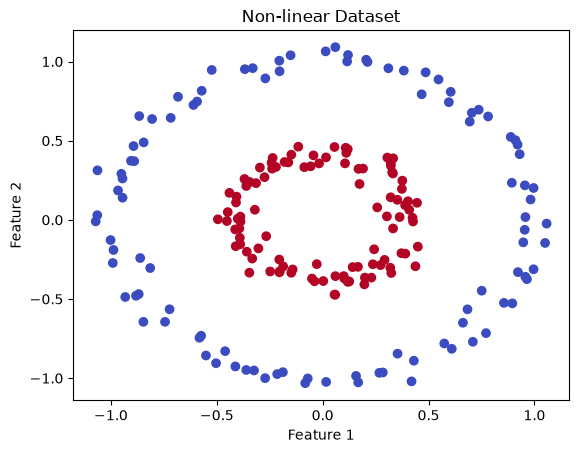

In [ ]:
# Linear과 RBF 비교
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.svm import SVC

# make_circles은 원형으로 분포된 분류 데이터를 생성한다.
X, y = make_circles(
    n_samples=200,
    factor=0.4,
    noise=0.05,
    random_state=42
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm"
)

plt.title("Non-linear Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
# 모델 생성 및 학습
linear_model = SVC(kernel="linear")
rbf_model = SVC(kernel="rbf")

linear_model.fit(X, y)
rbf_model.fit(X, y)

# 일반적으로 원형의 데이터에서는 RBF가 더 좋은 성능을 보인다.
print("Linear 정확도:", linear_model.score(X, y))
print("RBF 정확도:", rbf_model.score(X, y))

Linear 정확도: 0.585
RBF 정확도: 1.0


`RBF` 커널에서는 `C`이외에 `gamma`라는 중요한 하이퍼파라미터가 존재한다.

`gamma`는 개별학습 데이터의 영향 범위가 얼마나 넓게 퍼져있는지를 조절하는 값으로 이해하면 된다.

`C`값이 커질수록 하드마진이 되어가는 느낌같이, `gamma`가 **커지면 좁은 영향 범위의 결정 경계**를 만들게 된다.

| | Gamma 작음 | Gamma 큼 |
| --- | --- | --- |
| 데이터 영향 범위 | 넓음 | 좁음 |
| 결정 경계 | 상대적으로 부드러움 | 복잡해질 수 있음 |
| 주의할 점 | 과소적합 가능성 | 과적합 가능성 |

In [3]:
model_low = SVC(kernel="rbf", gamma=0.1)
model_high = SVC(kernel="rbf", gamma=100)

model_low.fit(X, y)
model_high.fit(X, y)

print("Gamma=0.1:", model_low.score(X, y))
print("Gamma=100:", model_high.score(X, y))

Gamma=0.1: 1.0
Gamma=100: 1.0


---
#### 실습문제

In [ ]:
from sklearn.datasets import make_moons
from sklearn.svm import SVC

X, y = make_moons(
    n_samples=300,
    noise=0.15,
    random_state=42
)

# 1. Linear 커널 SVM 생성 및 학습
linear_model = SVC(kernel="linear")
linear_model.fit(X, y)

# 2. RBF 커널 SVM 생성 및 학습
rbf_model = SVC(kernel="rbf")
rbf_model.fit(X, y)

# 3. Polynomial 커널 SVM 생성 및 학습
#    degree=3 사용
poly_model = SVC(kernel="poly", degree=3)
poly_model.fit(X, y)

# 4. 각 모델의 학습 정확도 출력
print(f"linear pred : {linear_model.score(X, y)}")
print(f"rbf pred : {rbf_model.score(X, y)}")
print(f"poly pred : {poly_model.score(X, y)}")

# 5. 가장 높은 학습 정확도를 기록한 모델 확인
# -> rbf 모델

# 1. gamma=0.01인 RBF SVM 생성 및 학습
rbf_model_less = SVC(kernel="rbf", gamma=0.01)
rbf_model_less.fit(X, y)

# 2. gamma=1인 RBF SVM 생성 및 학습
rbf_model_middle = SVC(kernel="rbf", gamma=1)
rbf_model_middle.fit(X, y)

# 3. gamma=100인 RBF SVM 생성 및 학습
rbf_model_high = SVC(kernel="rbf", gamma=100)
rbf_model_high.fit(X, y)

# 4. 각 모델의 학습 정확도 출력
rbf_models = {
    "Gamma 0.01" : rbf_model_less,
    "Gamma 1" : rbf_model_middle,
    "Gamma 100" : rbf_model_high
}

for name, model in rbf_models.items():
    print(f"{name} : {model.score(X, y)}")

# 5. 각 모델의 서포트 벡터 개수 출력
for name, model in rbf_models.items():
    print(f"{name} support vector : {model.n_support_}")

# 6. gamma 값에 따라 정확도가 어떻게 달라졌는지 설명
# -> gamma 값에 높아짐에 따라서 학습데이터에 대한 정확도는 높아질 수 있지만 과적합이 발생할 가능성이 있다.

linear pred : 0.8633333333333333
rbf pred : 0.9833333333333333
poly pred : 0.92
Gamma 0.1 : 0.84
Gamma 1 : 0.9833333333333333
Gamma 100 : 1.0
Gamma 0.1 support vector : [92 92]
Gamma 1 support vector : [28 29]
Gamma 100 support vector : [118 124]
